In [2]:
%pip install -q torch_geometric

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import torch
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.data import  Data

c:\Users\USER\Desktop\python\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\USER\Desktop\python\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:
# Features of 3 nodes (each node has 2 features)
x = torch.tensor([
    [1.0, 0.0],  # Node 0
    [0.0, 1.0],  # Node 1
    [1.0, 1.0]   # Node 2
])

In [5]:
# Connections between nodes
edge_index = torch.tensor([
    [0, 1, 1, 2],
    [1, 0, 2, 1]
])

In [6]:
# Create graph data
data=Data(x=x,edge_index=edge_index)

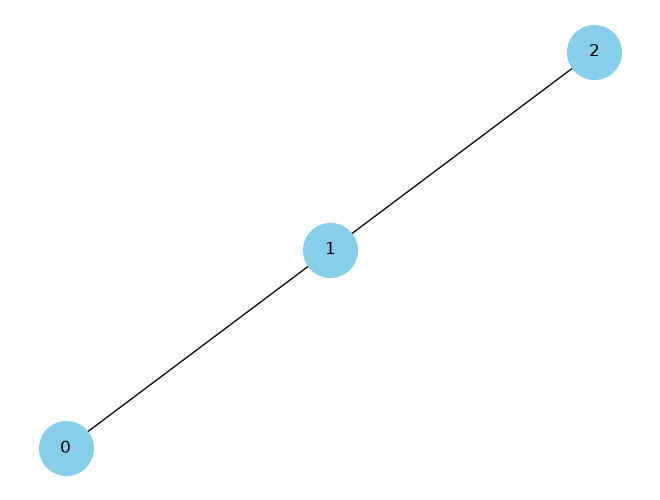

Data(x=[3, 2], edge_index=[2, 4])
Node features:
 tensor([[1., 0.],
        [0., 1.],
        [1., 1.]])
Edges:
 tensor([[0, 1, 1, 2],
        [1, 0, 2, 1]])


In [12]:
#Draw the graph
G=nx.Graph()
G.add_edges_from([(0, 1), (1, 2)])

nx.draw(G,with_labels=True,node_color="skyblue",node_size=1500)
plt.show()

print(data)
print("Node features:\n", data.x)
print("Edges:\n", data.edge_index)

In [13]:
from torch_geometric.nn import GCNConv

# A simple Graph Convolutional Network layer
conv = GCNConv(
    in_channels=2,
    out_channels=4
)

# Learn new features using node features and graph connections
out = conv(data.x, data.edge_index)

print("Input shape:", data.x.shape)
print("Output shape:", out.shape)
print(out)

Input shape: torch.Size([3, 2])
Output shape: torch.Size([3, 4])
tensor([[ 0.3050,  0.0487,  0.2552,  0.6083],
        [ 0.4664,  0.0564,  0.3766,  1.0145],
        [ 0.0933, -0.1057, -0.0120,  0.7488]], grad_fn=<AddBackward0>)
